In [9]:
# Cell 1: latest result for each (collection, config)
import pandas as pd
import matplotlib.pyplot as plt
from geoscholar import config

pd.set_option("display.width", 200)
RES = config.EVAL_DIR / "results"
summary = pd.read_csv(RES / "summary.csv")
latest = summary.sort_values("run_at").groupby(["collection", "config"]).tail(1)
order = ["dense", "bm25", "hybrid", "dense+rerank", "hybrid+rerank"]
c300 = latest[latest.collection == "papers_c300"].set_index("config").reindex(order).dropna(subset=["n"])
print(c300[["n", "recall@1", "recall@5", "recall@5_ci_low", "recall@5_ci_high", "recall@10", "mrr", "p50_ms"]].round(3))

                n  recall@1  recall@5  recall@5_ci_low  recall@5_ci_high  recall@10    mrr  p50_ms
config                                                                                            
dense          91     0.772     0.878            0.814             0.938      0.908  0.844     6.0
bm25           91     0.879     0.945            0.899             0.983      0.966  0.929    27.7
hybrid         91     0.818     0.952            0.913             0.985      0.993  0.901    36.1
dense+rerank   91     0.888     0.936            0.885             0.975      0.949  0.931   375.7
hybrid+rerank  91     0.912     0.972            0.947             0.993      0.984  0.954   403.7


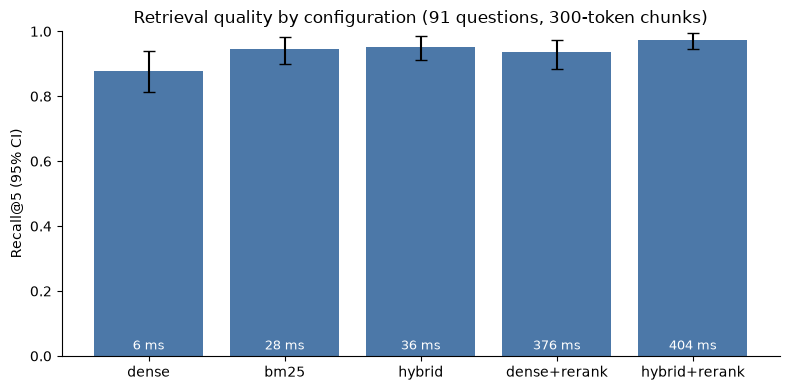

In [11]:
# Cell 2: recall@5 with confidence intervals, latency printed on each bar
fig, ax = plt.subplots(figsize=(8, 4))
err = [c300["recall@5"] - c300["recall@5_ci_low"], c300["recall@5_ci_high"] - c300["recall@5"]]
ax.bar(c300.index, c300["recall@5"], yerr=err, capsize=4, color="#4C78A8")
for i, ms in enumerate(c300["p50_ms"]):
    ax.text(i, 0.02, f"{ms:.0f} ms", ha="center", color="white", fontsize=9)
ax.set_ylim(0, 1)
ax.set_ylabel("Recall@5 (95% CI)")
ax.set_title(f"Retrieval quality by configuration ({int(c300['n'].iloc[0])} questions, 300-token chunks)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
(config.ROOT / "docs").mkdir(exist_ok=True)
plt.savefig(config.ROOT / "docs" / "retrieval_results.png", dpi=150)
plt.show()

In [13]:
# Cell 3: paired comparison of two configurations
from geoscholar.evaluation import bootstrap_ci

pq = pd.read_csv(RES / "per_question_papers_c300.csv")
hit = pq.pivot_table(index="qid", columns="config", values="recall@5")

def compare(a, b):
    diff = hit[a] - hit[b]
    lo, hi = bootstrap_ci(diff.values)
    verdict = "real difference" if lo > 0 or hi < 0 else "could be noise"
    print(f"{a} vs {b}: {diff.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  -> {verdict}")

compare("hybrid", "dense")
compare("dense+rerank", "dense")
compare("hybrid+rerank", "hybrid")
compare("hybrid+rerank", "dense")

hybrid vs dense: +0.074  95% CI [+0.026, +0.132]  -> real difference
dense+rerank vs dense: +0.058  95% CI [+0.012, +0.109]  -> real difference
hybrid+rerank vs hybrid: +0.020  95% CI [-0.004, +0.055]  -> could be noise
hybrid+rerank vs dense: +0.094  95% CI [+0.037, +0.159]  -> real difference


In [7]:
print(sorted(pq["config"].unique()))

['dense', 'hybrid+rerank']


In [15]:
# Cell 4: recall@5 by question type
by_type = pq.pivot_table(index="type", columns="config", values="recall@5", aggfunc="mean")[order]
print(by_type.round(3))

config            dense  bm25  hybrid  dense+rerank  hybrid+rerank
type                                                              
generated         0.901  1.00   0.972         0.958          1.000
generated-edited  1.000  1.00   1.000         1.000          1.000
manual            0.774  0.72   0.870         0.843          0.859


In [17]:
# Cell 5: chunk size comparison
sizes = latest[latest.config.isin(["dense", "hybrid+rerank"])].copy()
sizes["chunk_tokens"] = sizes.collection.str.extract(r"c(\d+)").astype(int)
print(sizes.pivot(index="chunk_tokens", columns="config", values=["recall@5", "mrr"]).round(3))

             recall@5                  mrr              
config          dense hybrid+rerank  dense hybrid+rerank
chunk_tokens                                            
150             0.889         0.952  0.894         0.947
300             0.878         0.972  0.844         0.954
450             0.878         0.952  0.845         0.957


In [19]:
# Cell 6: which questions each method wins or loses
hit = pq.pivot_table(index=["qid", "question"], columns="config", values="recall@5")[order]
pd.set_option("display.max_colwidth", 90)
print("Missed by every configuration:")
print(hit[(hit == 0).all(axis=1)].reset_index()["question"].to_string())
print("\nBM25 found it, dense did not:")
print(hit[(hit["bm25"] == 1) & (hit["dense"] == 0)].reset_index()["question"].to_string())
print("\nDense found it, BM25 did not:")
print(hit[(hit["dense"] == 1) & (hit["bm25"] == 0)].reset_index()["question"].to_string())
print("\nReranking made it worse:")
print(hit[(hit["hybrid"] == 1) & (hit["hybrid+rerank"] == 0)].reset_index()["question"].to_string())

Missed by every configuration:
Series([], )

BM25 found it, dense did not:
0    What are the retrieval performance values for DINOv3-B/16 with a frozen backbone on th...
1    What are the main limitations of recent hyperspectral classification methods in comple...
2    What is the number of parameters in the CAM used in the proposed method under the dete...
3    What is the classical optimum transform for compressing Gaussian sources under mean sq...
4    What remote sensing tools use past trajectories and execution experience to improve la...
5    What is the value of the exponential moving average (EMA) decay rate used to track per...
6    What are the two benchmark datasets used for hyperspectral image reconstruction experi...
7             How many modalities and which two spatial scales does the SomBench corpus cover?

Dense found it, BM25 did not:
0    Is updating only a small set of low-rank weights as good as updating every weight when...
1    How can radar images be rebuilt fr